In [1]:
#Easy: Implement the oracle for a constant function f(x)=0 and verify the algorithm outputs '0' (constant).
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

qc = QuantumCircuit(2, 1)

# Prepare |+>|->
qc.h(0)
qc.x(1)
qc.h(1)

# Oracle for f(x) = 0
# No gate is required

# Final Hadamard
qc.h(0)
qc.measure(0, 0)

sim = AerSimulator()
result = sim.run(qc, shots=1024).result()

print("Result:", result.get_counts())
print("Output 0 → Constant")

Result: {'0': 1024}
Output 0 → Constant


In [2]:
#● Medium: Implement the oracle for a balanced function f(x)=x and verify the algorithm outputs '1' (balanced).
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

qc = QuantumCircuit(2, 1)

# Prepare |+>|->
qc.h(0)
qc.x(1)
qc.h(1)

# Oracle for f(x) = x
qc.cx(0, 1)

# Final Hadamard
qc.h(0)
qc.measure(0, 0)

sim = AerSimulator()
result = sim.run(qc, shots=1024).result()

print("Result:", result.get_counts())
print("Output 1 → Balanced")

Result: {'1': 1024}
Output 1 → Balanced


In [3]:
#Hard: Build a generic oracle-selection function that takes a function type as a parameter and dynamically constructs the correct oracle circuit.
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

def deutsch(function_type):
    qc = QuantumCircuit(2, 1)

    # Prepare |+>|->
    qc.h(0)
    qc.x(1)
    qc.h(1)

    # Select oracle
    if function_type == "constant_0":
        pass
    elif function_type == "constant_1":
        qc.x(1)
    elif function_type == "balanced_x":
        qc.cx(0, 1)
    elif function_type == "balanced_not_x":
        qc.x(0)
        qc.cx(0, 1)
        qc.x(0)

    # Final Hadamard
    qc.h(0)
    qc.measure(0, 0)

    result = AerSimulator().run(qc, shots=1024).result()
    return result.get_counts()


for f in ["constant_0", "constant_1", "balanced_x", "balanced_not_x"]:
    print(f, ":", deutsch(f))

constant_0 : {'0': 1024}
constant_1 : {'0': 1024}
balanced_x : {'1': 1024}
balanced_not_x : {'1': 1024}


In [4]:
#Real-world: Extend the demonstration to explain, with a simple slide/diagram, how phase kickback could conceptually apply to a binary classification decision problem. giv ethe code 
from qiskit import QuantumCircuit

qc = QuantumCircuit(2)

# Input and auxiliary qubit
qc.h(0)
qc.x(1)
qc.h(1)

# Classification oracle: f(x) = x
qc.cx(0, 1)

# Phase kickback
qc.h(0)

print(qc)
print("\nBinary Classification:")
print("f(x) = 0 → Class 0")
print("f(x) = 1 → Class 1")
print("Phase kickback encodes the classification information in the control qubit.")

     ┌───┐          ┌───┐
q_0: ┤ H ├───────■──┤ H ├
     ├───┤┌───┐┌─┴─┐└───┘
q_1: ┤ X ├┤ H ├┤ X ├─────
     └───┘└───┘└───┘     

Binary Classification:
f(x) = 0 → Class 0
f(x) = 1 → Class 1
Phase kickback encodes the classification information in the control qubit.


Error = 0
Counts = {'0': 1000}
Correct probability = 0.0

Error = 0.05
Counts = {'0': 1000}
Correct probability = 0.0

Error = 0.1
Counts = {'0': 1000}
Correct probability = 0.0

Error = 0.15
Counts = {'0': 1000}
Correct probability = 0.0

Error = 0.2
Counts = {'0': 1000}
Correct probability = 0.0



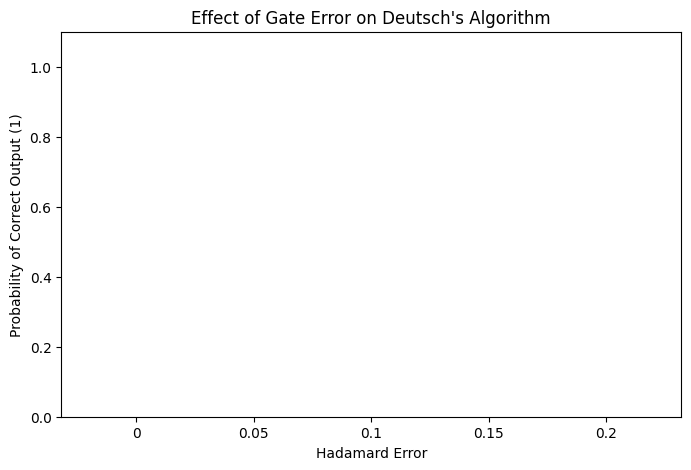

In [6]:
#● Challenge: Modify the circuit to introduce a deliberate small gate error (imperfect Hadamard) and study how measurement outcome reliability degrades; quantify with a bar chart.
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

sim = AerSimulator()

def run_deutsch(error):
    qc = QuantumCircuit(2, 1)

    # Imperfect H gate on control qubit
    qc.ry(np.pi/2 + error, 0)

    # Prepare target qubit in |-> state
    qc.x(1)
    qc.h(1)

    # Balanced oracle f(x) = x
    qc.cx(0, 1)

    # Imperfect H gate
    qc.ry(np.pi/2 + error, 0)

    # Measure control qubit
    qc.measure(0, 0)

    result = sim.run(qc, shots=1000).result()
    counts = result.get_counts()

    # Count output '1'
    correct = sum(
        count for key, count in counts.items()
        if key.replace(" ", "") == "1"
    )

    return correct / 1000, counts


# Different Hadamard errors
errors = [0, 0.05, 0.10, 0.15, 0.20]

reliability = []

for error in errors:
    probability, counts = run_deutsch(error)
    reliability.append(probability)

    print("Error =", error)
    print("Counts =", counts)
    print("Correct probability =", probability)
    print()


# Bar chart
plt.figure(figsize=(8, 5))
plt.bar([str(e) for e in errors], reliability)

plt.xlabel("Hadamard Error")
plt.ylabel("Probability of Correct Output (1)")
plt.title("Effect of Gate Error on Deutsch's Algorithm")

plt.ylim(0, 1.1)
plt.show()